In [2]:
import numpy as np
import pandas as pd

df = pd.DataFrame({
    "Name": ["Asha", "Rahul", "Priya", "Kiran"],
    "Age": [20, 25, 30, 35],
    "Marks": [85, 42, 92, 68],
    "City": ["Hyderabad", "Mumbai", "Hyderabad", "Chennai"]
})

df

,Name,Age,Marks,City
0,Asha,20,85,Hyderabad
1,Rahul,25,42,Mumbai
2,Priya,30,92,Hyderabad
3,Kiran,35,68,Chennai


In [4]:
df["Grade"]=df["Marks"].map(
    lambda x: "Pass" if x>=40 else "Fail"
)
df

,Name,Age,Marks,City,Grade
0,Asha,20,85,Hyderabad,Pass
1,Rahul,25,42,Mumbai,Pass
2,Priya,30,92,Hyderabad,Pass
3,Kiran,35,68,Chennai,Pass


In [6]:
df["Age_Next_Year"] = df["Age"].apply(lambda x: x + 1)

df["Average"] = df[["Age", "Marks"]].mean(axis=1)

df

,Name,Age,Marks,City,Grade,Age_Next_Year,Average
0,Asha,20,85,Hyderabad,Pass,21,52.5
1,Rahul,25,42,Mumbai,Pass,26,33.5
2,Priya,30,92,Hyderabad,Pass,31,61.0
3,Kiran,35,68,Chennai,Pass,36,51.5


In [8]:
df["Marks_Bonus"] = df["Marks"] + 5
df["Marks_Percentage"] = df["Marks"] / 100
df

,Name,Age,Marks,City,Grade,Age_Next_Year,Average,Marks_Bonus,Marks_Percentage
0,Asha,20,85,Hyderabad,Pass,21,52.5,90,0.85
1,Rahul,25,42,Mumbai,Pass,26,33.5,47,0.42
2,Priya,30,92,Hyderabad,Pass,31,61.0,97,0.92
3,Kiran,35,68,Chennai,Pass,36,51.5,73,0.68


In [9]:
df["City"] = df["City"].str.strip().str.title()

print(df["City"].str.contains("hyd", case=False, na=False))
print(df["Name"].str.lower())

0     True
1    False
2     True
3    False
Name: City, dtype: bool
0     asha
1    rahul
2    priya
3    kiran
Name: Name, dtype: str


In [10]:
sales = pd.DataFrame({
    "Date": ["2026-01-15", "2026-02-20", "invalid"],
    "Revenue": [1000, 1500, 800]
})

sales["Date"] = pd.to_datetime(sales["Date"], errors="coerce")

sales["Year"] = sales["Date"].dt.year
sales["Month"] = sales["Date"].dt.month
sales["DayOfWeek"] = sales["Date"].dt.dayofweek

print(sales)

        Date  Revenue    Year  Month  DayOfWeek
0 2026-01-15     1000  2026.0    1.0        3.0
1 2026-02-20     1500  2026.0    2.0        4.0
2        NaT      800     NaN    NaN        NaN


C:\Users\SAMSUNG\AppData\Local\Temp\ipykernel_17288\2079445457.py:10: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  sales["DayOfWeek"] = sales["Date"].dt.dayofweek


In [11]:
print(df["City"].value_counts())
print(df["City"].unique())
print(df["City"].nunique())

City
Hyderabad    2
Mumbai       1
Chennai      1
Name: count, dtype: int64
<StringArray>
['Hyderabad', 'Mumbai', 'Chennai']
Length: 3, dtype: str
3


In [12]:
df["City"] = df["City"].astype("category")

In [16]:
sales = pd.DataFrame({
    "City": ["Hyd", "Hyd", "Chennai", "Chennai"],
    "Year": [2025, 2026, 2025, 2026],
    "Revenue": [100, 150, 80, 120]
})

wide = sales.pivot(
    index="City",
    columns="Year",
    values="Revenue",
)

print(wide)

Year     2025  2026
City               
Chennai    80   120
Hyd       100   150


In [15]:
summary = sales.pivot_table(
    index="City",
    columns="Year",
    values="Revenue",
    aggfunc="sum"
)

summary

Year,2025,2026
City,,
Chennai,80,120
Hyd,100,150


In [17]:
# Dataset structure
print(df.shape)
print(df.info())
print(df.describe(include="all"))

# Missing values
print(df.isna().sum())

# Duplicates
print(df.duplicated().sum())

# Numerical correlations
print(df.select_dtypes(include="number").corr())

# Distributions and categorical frequencies
print(df["Marks"].value_counts())
print(df.groupby("City")["Marks"].mean())

(4, 9)
<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   Name              4 non-null      str     
 1   Age               4 non-null      int64   
 2   Marks             4 non-null      int64   
 3   City              4 non-null      category
 4   Grade             4 non-null      str     
 5   Age_Next_Year     4 non-null      int64   
 6   Average           4 non-null      float64 
 7   Marks_Bonus       4 non-null      int64   
 8   Marks_Percentage  4 non-null      float64 
dtypes: category(1), float64(2), int64(4), str(2)
memory usage: 416.0 bytes
None
        Name        Age      Marks       City Grade  Age_Next_Year    Average  \
count      4   4.000000   4.000000          4     4       4.000000   4.000000   
unique     4        NaN        NaN          3     1            NaN        NaN   
top     Asha        NaN        NaN  Hyderabad  Pass 

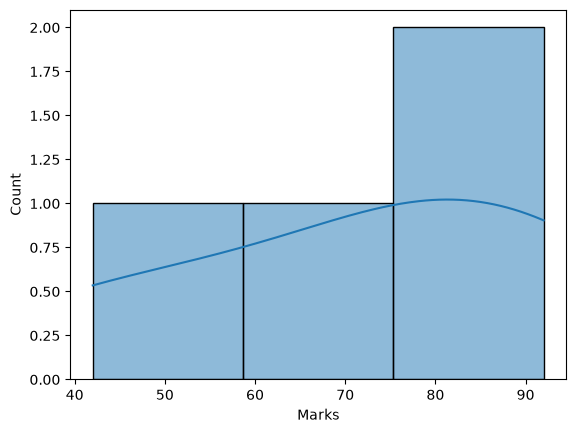

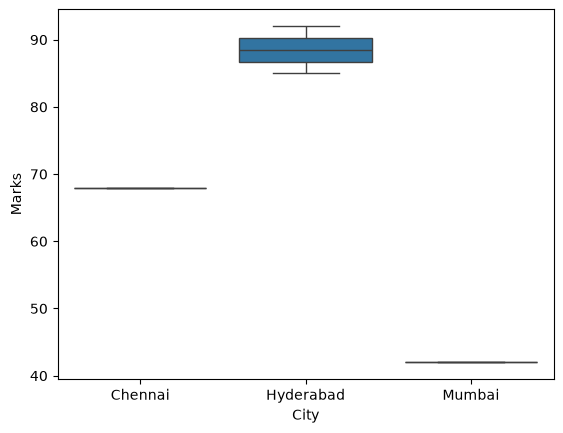

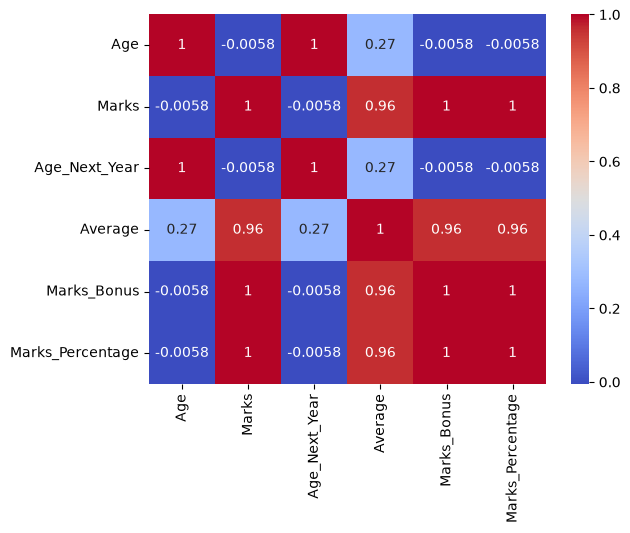

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df["Marks"], kde=True)
plt.show()

sns.boxplot(data=df, x="City", y="Marks")
plt.show()

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm"
)
plt.show()

In [21]:
df["Marks_Category"] = pd.cut(
    df["Marks"],
    bins=[0, 40, 60, 80, 100],
    labels=["Low", "Average", "Good", "Excellent"],
    include_lowest=True
)

df["Is_High_Scorer"] = (df["Marks"] >= 80).astype(int)

df

,Name,Age,Marks,City,Grade,Age_Next_Year,Average,Marks_Bonus,Marks_Percentage,Marks_Category,Is_High_Scorer
0,Asha,20,85,Hyderabad,Pass,21,52.5,90,0.85,Excellent,1
1,Rahul,25,42,Mumbai,Pass,26,33.5,47,0.42,Average,0
2,Priya,30,92,Hyderabad,Pass,31,61.0,97,0.92,Excellent,1
3,Kiran,35,68,Chennai,Pass,36,51.5,73,0.68,Good,0


In [22]:
from sklearn.model_selection import train_test_split

X = df[["Age", "Marks"]]
y = df["Grade"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [23]:
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# 1. Convert text grades into numbers (e.g., 'A'->0, 'B'->1)
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

# 2. Initialize the classification model
model = DecisionTreeClassifier(random_state=42)

# 3. TRAIN: Let the model find patterns between (Age, Marks) and the numeric Grade
model.fit(X_train, y_train_encoded)

# 4. PREDICT: Ask the model to guess the grades for the hidden test data
y_pred = model.predict(X_test)

# 5. EVALUATE: See what percentage of the test set the model guessed correctly
accuracy = accuracy_score(y_test_encoded, y_pred)
print(f"Classification Accuracy: {accuracy * 100:.2f}%")


Classification Accuracy: 100.00%


In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# 1. Initialize the regression model
model = LinearRegression()

# 2. TRAIN: Let the model find the mathematical line fitting the data
model.fit(X_train, y_train_encoded)

# 3. PREDICT: Have the model estimate numerical grades for the test data
y_pred = model.predict(X_test)

# 4. EVALUATE: Calculate the average margin of error (lower is better)
mae = mean_absolute_error(y_test_encoded, y_pred)
print(f"Average Error: The model's guesses are off by an average of {mae:.2f} points.")


Average Error: The model's guesses are off by an average of 0.00 points.
